# Comparing authors by word frequency
Harrison Crettol, CS 445 Mini Project 1

My first idea was to compare two authors and find what words they both used the most. After thinking about it more, I realized that it would most likely result in the most commonly used words, such as, "the", "and", "a". So instead I'm looking at where authors differ.

I'm comparing three pairs that get progressively harder to tell apart:

1. Macbeth vs Romeo and Juliet (same author, so this is my baseline)
2. Shakespeare vs Dr. Seuss (should be easy)
3. Shakespeare vs Christopher Marlowe (should be hard)

Marlowe is the one I actually care about. He was born the same year as Shakespeare and wrote for the same theaters, so if word frequencies can still separate them then the method is picking up something real about the writing and not just the time period or the genre.

## Where the data comes from

All three plays are from Project Gutenberg and get downloaded by the cell below. I originally had Macbeth and Romeo and Juliet from the Folger library instead, but mixing sources is a bad idea here: different editors make different spelling and formatting choices, so some of the "differences" I found would have been the editors and not the authors.

Green Eggs and Ham is the exception. It's from 1960 and still under copyright, so there's nowhere legitimate to download it from. Mine is a transcription I found online and it has typos in it. I'm keeping it because it's a useful extreme case but it's the weakest text in the set.

In [1]:
import os, re, math
from collections import Counter
import matplotlib.pyplot as plt
import requests
from scipy.stats import norm

os.makedirs("data", exist_ok=True)

# filename -> (title, author, gutenberg id)
SOURCES = {
    "shakespeare_macbeth.txt":      ("Macbeth",          "Shakespeare", 1533),
    "shakespeare_romeo_juliet.txt": ("Romeo and Juliet", "Shakespeare", 1513),
    "marlowe_faustus.txt":          ("Doctor Faustus",   "Marlowe",      779),
}

for filename, (title, author, pg_id) in SOURCES.items():
    path = os.path.join("data", filename)
    if os.path.exists(path):
        print("already have", path)
        continue
    url = f"https://www.gutenberg.org/cache/epub/{pg_id}/pg{pg_id}.txt"
    r = requests.get(url, timeout=30)
    r.raise_for_status()
    with open(path, "w", encoding="utf-8") as f:
        f.write(r.text)
    print(f"downloaded {path}  ({len(r.text.split()):,} words)")

# make sure I actually got the right plays
print()
for filename in SOURCES:
    with open(os.path.join("data", filename), encoding="utf-8") as f:
        head = f.read(1500)
    line = next((l for l in head.splitlines() if l.startswith("Title:")), "no Title line found")
    print(filename, "->", line)

already have data/shakespeare_macbeth.txt
already have data/shakespeare_romeo_juliet.txt
already have data/marlowe_faustus.txt

shakespeare_macbeth.txt -> Title: Macbeth
shakespeare_romeo_juliet.txt -> Title: Romeo and Juliet
marlowe_faustus.txt -> Title: The Tragical History of Doctor Faustus


## Cleaning

Gutenberg puts a few hundred words of license text at the top and bottom of every file. I cut that out, otherwise I'd be counting the same boilerplate in every book.

Then I lowercase everything so "The" and "the" count as the same word, keep apostrophes inside words so "don't" stays whole, and drop numbers and punctuation.

In [2]:
def strip_gutenberg(text):
    start = re.search(r"\*\*\*\s*START OF TH[EIS]+ PROJECT GUTENBERG EBOOK.*?\*\*\*", text, re.I)
    end   = re.search(r"\*\*\*\s*END OF TH[EIS]+ PROJECT GUTENBERG EBOOK.*?\*\*\*", text, re.I)
    return text[(start.end() if start else 0):(end.start() if end else len(text))]

def words_of(text):
    text = text.lower().replace("\u2019", "'")   # curly apostrophes -> straight
    return re.findall(r"[a-z]+(?:'[a-z]+)?", text)

def load(path):
    with open(path, encoding="utf-8", errors="replace") as f:
        return words_of(strip_gutenberg(f.read()))

texts = {
    "Macbeth":            load("data/shakespeare_macbeth.txt"),
    "Romeo and Juliet":   load("data/shakespeare_romeo_juliet.txt"),
    "Doctor Faustus":     load("data/marlowe_faustus.txt"),
    "Green Eggs and Ham": load("data/seuss_green_eggs_and_ham.txt"),
}

for name, w in texts.items():
    print(f"{name:<20} {len(w):>7,} words   {len(set(w)):>6,} distinct")

Macbeth               18,566 words    3,379 distinct
Romeo and Juliet      26,122 words    3,742 distinct
Doctor Faustus        19,697 words    3,657 distinct
Green Eggs and Ham       806 words       57 distinct


Those numbers are the reason I can't just compare counts. Green Eggs and Ham is a few hundred words with a tiny vocabulary and the plays are tens of thousands of words. If "not" shows up more times in Macbeth, all that tells me is that Macbeth is longer.

So everything below uses a rate per 10,000 words instead of a count. Same idea as using crime per capita instead of total crimes.

In [3]:
def rate_table(words, per=10000):
    counts = Counter(words)
    n = len(words)
    return {w: c * per / n for w, c in counts.items()}, counts, n

rates, counts, totals = {}, {}, {}
for name, w in texts.items():
    rates[name], counts[name], totals[name] = rate_table(w)

# this is my original question, and it's a dead end
for name in texts:
    top = sorted(rates[name].items(), key=lambda kv: -kv[1])[:8]
    print(f"{name:<20}", "  ".join(f"{w}({r:.0f})" for w, r in top))

Macbeth              the(393)  and(307)  to(206)  of(193)  i(186)  macbeth(152)  a(149)  in(123)
Romeo and Juliet     and(282)  the(264)  i(223)  to(207)  a(187)  of(151)  my(136)  that(132)
Doctor Faustus       the(439)  and(291)  of(267)  to(227)  faustus(205)  i(194)  in(161)  a(152)
Green Eggs and Ham   i(1030)  not(1017)  them(732)  a(695)  like(546)  in(496)  do(459)  you(422)


Every single text is topped by the same function words, which is what I expected. Whatever separates these authors is in how the rates differ, not in the ranking.

## Finding the words that separate two texts

For each word I divide its rate in text A by its rate in text B and take log base 2, so +1 means twice as common in A and -1 means twice as common in B. I add 1 to each count first so a missing word doesn't break the division, and I ignore anything appearing under 10 times total so a rare word can't top the list by luck.

I also drop character and place names. Obviously "Macbeth" appears a lot in Macbeth, but that says nothing about how Shakespeare writes, and those names were crowding out everything else. Deciding to remove them is a judgment call on my part and I mention it in my limitations.

In [4]:
# names to ignore. I built this by looking at the output and adding whatever
# was obviously just a character or a place, so it's probably still incomplete.
NAMES = {
    "macbeth","banquo","duncan","malcolm","donalbain","macduff","lennox","ross",
    "menteith","angus","caithness","fleance","siward","seyton","hecate","scotland",
    "cawdor","thane","dunsinane","birnam","glamis",
    "romeo","juliet","tybalt","mercutio","benvolio","capulet","montague","escalus",
    "laurence","lawrence","balthasar","sampson","gregory","peter","verona","mantua",
    "faustus","mephistopheles","mephistophilis","wagner","lucifer","belzebub",
    "valdes","cornelius","wittenberg",
    "sam",
}

def distinctive(name_a, name_b, min_total=10, top=12, vocab=None):
    ca, cb = counts[name_a], counts[name_b]
    na, nb = totals[name_a], totals[name_b]
    rows = []
    for w in set(ca) | set(cb):
        if w in NAMES:
            continue
        if vocab is not None and w not in vocab:
            continue
        if ca[w] + cb[w] < min_total:
            continue
        ra = (ca[w] + 1) / (na + 1)
        rb = (cb[w] + 1) / (nb + 1)
        rows.append((math.log2(ra / rb), w, ra * 10000, rb * 10000))
    rows.sort()
    return rows[-top:][::-1], rows[:top]

def show(name_a, name_b, **kw):
    hi, lo = distinctive(name_a, name_b, **kw)
    print(f"\n{name_a} vs {name_b}")
    print(f"\n  more {name_a}:")
    for score, w, ra, rb in hi[:8]:
        print(f"    {w:<14} {score:+5.2f}   {ra:6.1f} vs {rb:6.1f} per 10k")
    print(f"\n  more {name_b}:")
    for score, w, ra, rb in lo[:8]:
        print(f"    {w:<14} {score:+5.2f}   {ra:6.1f} vs {rb:6.1f} per 10k")

show("Macbeth", "Romeo and Juliet")


Macbeth vs Romeo and Juliet

  more Macbeth:
    witch          +6.22     28.5 vs    0.4 per 10k
    th             +6.14     26.9 vs    0.4 per 10k
    doctor         +5.54     17.8 vs    0.4 per 10k
    castle         +5.19     14.0 vs    0.4 per 10k
    does           +5.14     13.5 vs    0.4 per 10k
    has            +4.81     10.8 vs    0.4 per 10k
    hail           +4.66      9.7 vs    0.4 per 10k
    king           +4.08     19.4 vs    1.1 per 10k

  more Romeo and Juliet:
    nurse          -6.74      0.5 vs   57.4 per 10k
    friar          -6.22      0.5 vs   40.2 per 10k
    paris          -5.46      0.5 vs   23.7 per 10k
    capulet's      -4.03      0.5 vs    8.8 per 10k
    cell           -4.03      0.5 vs    8.8 per 10k
    banished       -3.90      0.5 vs    8.0 per 10k
    married        -3.83      0.5 vs    7.7 per 10k
    ah             -3.59      0.5 vs    6.5 per 10k


**My notes:** _(are these words about style, or about what the play is about?)_

## The two-author comparisons

Green Eggs and Ham needs one extra step. Its whole vocabulary is under 60 words, so "Shakespeare uses thousands of words Seuss never uses" is true but meaningless, it's a fact about length. To make it fair I only look at words Seuss actually uses and ask whether Shakespeare uses those at different rates.

In [5]:
show("Macbeth", "Doctor Faustus")

seuss_vocab = set(texts["Green Eggs and Ham"])
print(f"\n\nSeuss vocabulary is only {len(seuss_vocab)} words, so restricting to those:")
show("Macbeth", "Green Eggs and Ham", vocab=seuss_vocab, min_total=15)


Macbeth vs Doctor Faustus

  more Macbeth:
    witch          +5.81     28.5 vs    0.5 per 10k
    murderer       +5.21     18.9 vs    0.5 per 10k
    son            +5.04     16.7 vs    0.5 per 10k
    worthy         +4.26      9.7 vs    0.5 per 10k
    knocking       +4.26      9.7 vs    0.5 per 10k
    hail           +4.26      9.7 vs    0.5 per 10k
    act            +4.09      8.6 vs    0.5 per 10k
    sword          +3.89      7.5 vs    0.5 per 10k

  more Doctor Faustus:
    footnote       -7.38      0.5 vs   89.9 per 10k
    tos            -6.20      0.5 vs   39.6 per 10k
    mephist        -6.16      0.5 vs   38.6 per 10k
    e              -5.56      0.5 vs   25.4 per 10k
    ed             -5.08      0.5 vs   18.3 per 10k
    later          -5.02      1.1 vs   35.0 per 10k
    history        -5.00      0.5 vs   17.3 per 10k
    robin          -4.87      0.5 vs   15.7 per 10k


Seuss vocabulary is only 57 words, so restricting to those:

Macbeth vs Green Eggs and Ham

  more

**My notes:** _(which pair was easier to separate? anything unexpected in the Faustus results?)_

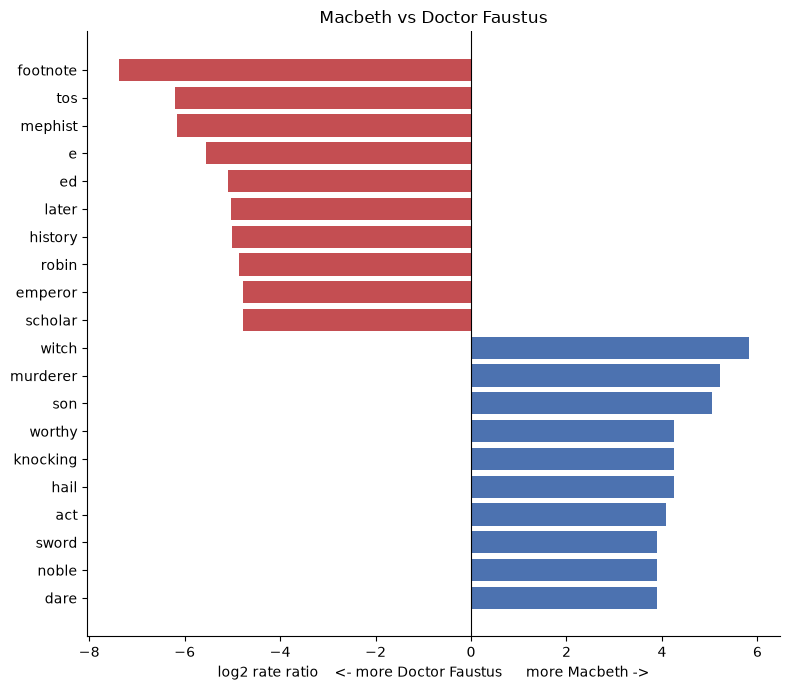

In [6]:
def plot_distinctive(name_a, name_b, top=10, **kw):
    hi, lo = distinctive(name_a, name_b, top=top, **kw)
    rows = list(reversed(hi)) + lo[::-1]
    labels = [r[1] for r in rows]
    scores = [r[0] for r in rows]
    colors = ["#4C72B0" if s > 0 else "#C44E52" for s in scores]

    fig, ax = plt.subplots(figsize=(8, 7))
    ax.barh(range(len(rows)), scores, color=colors)
    ax.set_yticks(range(len(rows)))
    ax.set_yticklabels(labels)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_xlabel(f"log2 rate ratio    <- more {name_b}      more {name_a} ->")
    ax.set_title(f"{name_a} vs {name_b}")
    ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    plt.show()

plot_distinctive("Macbeth", "Doctor Faustus")

## Extra credit: is the difference real or just chance?

Picking the biggest ratios isn't quite enough, since a word could look lopsided by luck.

The setup from the assignment: treat every word in a text as a trial where with probability p that word is "would". Then the number of times "would" appears is binomial, and p is estimated by (times "would" appears) / (total words). Comparing two texts is then a two-proportion test, which asks how many standard errors apart the two estimates are. A p-value under 0.05 means a gap this big would be unlikely to happen by chance.

The row I'm watching is the same-author one. If two Shakespeare plays come out significantly different, then "significant difference" on its own can't prove two texts had different authors.

In [7]:
def two_proportion_test(word, name_a, name_b):
    ca, cb = counts[name_a][word], counts[name_b][word]
    na, nb = totals[name_a], totals[name_b]
    pa, pb = ca / na, cb / nb
    pooled = (ca + cb) / (na + nb)
    se = math.sqrt(pooled * (1 - pooled) * (1 / na + 1 / nb))
    if se == 0:
        return None
    z = (pa - pb) / se
    return pa * 10000, pb * 10000, z, 2 * norm.sf(abs(z))

PAIRS = [
    ("Macbeth", "Romeo and Juliet"),      # same author
    ("Macbeth", "Doctor Faustus"),        # same era, different author
    ("Macbeth", "Green Eggs and Ham"),    # nothing in common
]

for word in ["would", "not", "the", "my"]:
    print(f"\n'{word}'")
    print(f"{'':<40} {'rate A':>8} {'rate B':>8} {'z':>7} {'p':>11}")
    for a, b in PAIRS:
        res = two_proportion_test(word, a, b)
        if res is None:
            continue
        ra, rb, z, p = res
        print(f"{a + ' vs ' + b:<40} {ra:8.1f} {rb:8.1f} {z:+7.2f} {p:11.3g}"
              + ("  *" if p < 0.05 else ""))


'would'
                                           rate A   rate B       z           p
Macbeth vs Romeo and Juliet                  25.3     20.7   +1.02       0.308
Macbeth vs Doctor Faustus                    25.3     22.8   +0.49       0.622
Macbeth vs Green Eggs and Ham                25.3    335.0  -13.95    3.05e-44  *

'not'
                                           rate A   rate B       z           p
Macbeth vs Romeo and Juliet                  88.9     99.2   -1.10       0.269
Macbeth vs Doctor Faustus                    88.9     77.7   +1.21       0.228
Macbeth vs Green Eggs and Ham                88.9   1017.4  -23.00   4.56e-117  *

'the'
                                           rate A   rate B       z           p
Macbeth vs Romeo and Juliet                 393.2    263.8   +7.69    1.47e-14  *
Macbeth vs Doctor Faustus                   393.2    438.6   -2.22      0.0262  *
Macbeth vs Green Eggs and Ham               393.2    136.5   +3.72    0.000199  *

'my'
        

**My notes:** _(what does the same-author row mean for the method?)_

## Findings

**What is the question?**

_(write here)_

**What was the approach?**

_(write here)_

**What problems did I encounter?**

_(write here. so far: the size mismatch between texts, Gutenberg boilerplate inflating counts, character names dominating the results until I filtered them, editorial footnotes contaminating the Faustus text, my tokenizer splitting "th'" into "th", and Green Eggs and Ham having no real source and containing typos)_

**What results did I get?**

_(write here)_

**What new ideas did this generate?**

_(write here)_